# Регрессия и сравнение моделей

**Исследуемые алгоритмы** — DummyRegressor (базовый ориентир), LinearRegression, Ridge, Lasso, RandomForestRegressor, XGBRegressor, MLPRegressor.


## Методика и организация данных

В предобработке данных из 1 460 домов выделены 1 168 объектов для обучения и 292 объекта для внешнего тестирования. Сохраняем то же исходное разбиение по `Id`. Для кросс-валидации используются исходные характеристики обучающей выборки, а не заранее преобразованная матрица `X_train_reg.csv`.

**Фолд (fold)** — один из пяти непересекающихся блоков обучающих объектов. При 5-Fold CV модель обучается пять раз, каждый раз на четырёх блоках (около 934–935 домов), а оставшийся блок (233–234 дома) служит для проверки. Каждый дом участвует в проверке ровно один раз. Разбиения перемешиваются и воспроизводятся с `random_state=42`.

В каждом повторении создаётся новая копия Pipeline. Инженерия признаков, заполнение пропусков, IQR-ограничения, One-Hot Encoding и StandardScaler настраиваются исключительно по четырём обучающим блокам. К проверочному блоку применяется только `transform()`. Таким образом, статистики предобработки не попадают из валидации в обучение.

Качество оценивается по MAE (средней абсолютной ошибке в USD), RMSE (корню из средней квадратичной ошибки в USD) и **R² (коэффициенту детерминации)**. В отличие от MAE и RMSE, R² безразмерен и сопоставляет сумму квадратов ошибок модели с ошибкой простого прогноза среднего значения проверочной выборки:

$$
R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}.
$$

Значение R² = 1 соответствует точным предсказаниям, R² = 0 соответствует по сумме квадратов ошибок прогнозу среднего значения, отрицательный R² означает результат хуже такого ориентира. **R² = 0,89 не означает, что цена угадана с точностью 89%**. В таблице CV показано среднее пяти отдельных R², поэтому оно не тождественно R², рассчитанному на всех объединённых прогнозах.

Внешние 292 объекта не используются при выборе гиперпараметров. Поскольку в предыдущих экспериментах мы уже изучали отдельные тестовые дома, результаты внешнего теста рассматриваются как дополнительные описательные оценки, а не как полностью нетронутая независимая проверка.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image, Markdown

# Открывается и из корня репозитория, и из каталога notebooks/.
ROOT = next((p for p in (Path.cwd(), Path.cwd().parent) if (p / "house_prices_ai").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Откройте JupyterLab в каталоге репозитория House Prices AI")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from house_prices_ai.config import PROJECT_ROOT, OUTPUT_DIR
from house_prices_ai.regression import load_lr02_split, run_regression

RESULTS = OUTPUT_DIR / "regression"
FIGURES = RESULTS / "figures"

X_train, X_test, y_train, y_test = load_lr02_split()
print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Цель: {y_train.name}, диапазон SalePrice: {y_train.min():,.0f}–{y_train.max():,.0f} USD")

Train: (1168, 79), Test: (292, 79)
Цель: SalePrice, диапазон SalePrice: 34,900–755,000 USD


## Выполнение сравнительного эксперимента

Если результаты ещё не созданы, первая команда автоматически запускает обучение и 5-Fold CV. Если файлы уже присутствуют после `python run_lr03.py`, они используются повторно. Для полного подбора параметров XGBoost отдельно выполнить `python run_lr03.py --tune-xgb`.

Параметры базовых моделей не выбираются по тесту. Для MLP масштабируется также `SalePrice`, внутренний механизм Early Stopping использует дополнительную валидацию из обучающего фолда.

In [2]:
if not (RESULTS / "cv_clean_summary.csv").exists():
    run_regression(folds=5, tune=False, make_plots=True)

cv_summary = pd.read_csv(RESULTS / "cv_clean_summary.csv")
cv_folds = pd.read_csv(RESULTS / "cv_clean_folds.csv")
test_summary = pd.read_csv(RESULTS / "test_descriptive.csv")

display(cv_summary.round(4))

,Model,R2_mean,R2_std,Train_R2_mean,MAE_mean,MAE_std,RMSE_mean,RMSE_std
0,XGBoost,0.8903,0.0488,0.9822,14959.3280,1600.4618,25785.5023,6387.7708
1,Random Forest,0.8664,0.0481,0.9790,16937.0983,1643.4805,28691.9553,5011.7075
2,Lasso,0.8150,0.1040,0.9226,17681.3522,1807.6080,32830.4711,8117.2174
3,Ridge,0.8019,0.1090,0.9187,18357.0862,1682.4848,34107.6720,8517.4640
4,LinearRegression,0.5521,0.4874,0.9552,20240.3328,2851.4024,46382.3205,22284.8726
5,MLP,0.7385,0.1496,0.9119,21357.2538,3242.5034,39290.1109,10058.2001
6,DummyRegressor,-0.0070,0.0093,0.0000,57501.5657,2524.5457,80255.0065,7051.9135


Сопоставим средние R², MAE и RMSE с их разбросом между фолдами. Большое стандартное отклонение `R2_std` указывает на зависимость качества от состава проверочного блока, а разница `Train_R2_mean − R2_mean` помогает выявить переобучение или нестабильность модели.

In [3]:
print("R² на пяти разбиениях:")
display(cv_folds.pivot(index="Fold", columns="Model", values="R2").round(4))

best_model_name = str(cv_summary.iloc[0]["Model"])
print(f"Лучший алгоритм по CV MAE: {best_model_name}")

R² на пяти разбиениях:


Model,DummyRegressor,Lasso,LinearRegression,MLP,Random Forest,Ridge,XGBoost
Fold,,,,,,,
1,-0.0015,0.7759,0.5879,0.7284,0.8359,0.7482,0.8204
2,-0.0058,0.9088,0.8158,0.8067,0.9103,0.8961,0.9427
3,-0.0008,0.6295,-0.3986,0.4584,0.7862,0.6116,0.8448
4,-0.0016,0.8999,0.8982,0.8049,0.8969,0.8885,0.9326
5,-0.0252,0.8609,0.8574,0.8942,0.9029,0.8649,0.9112


Лучший алгоритм по CV MAE: XGBoost


## Сравнение метрик и устойчивости

Диаграммы сделаны на белом фоне для печати на книжном листе A4. Подписи вынесены **под** рисунки (сквозная нумерация главы 3).

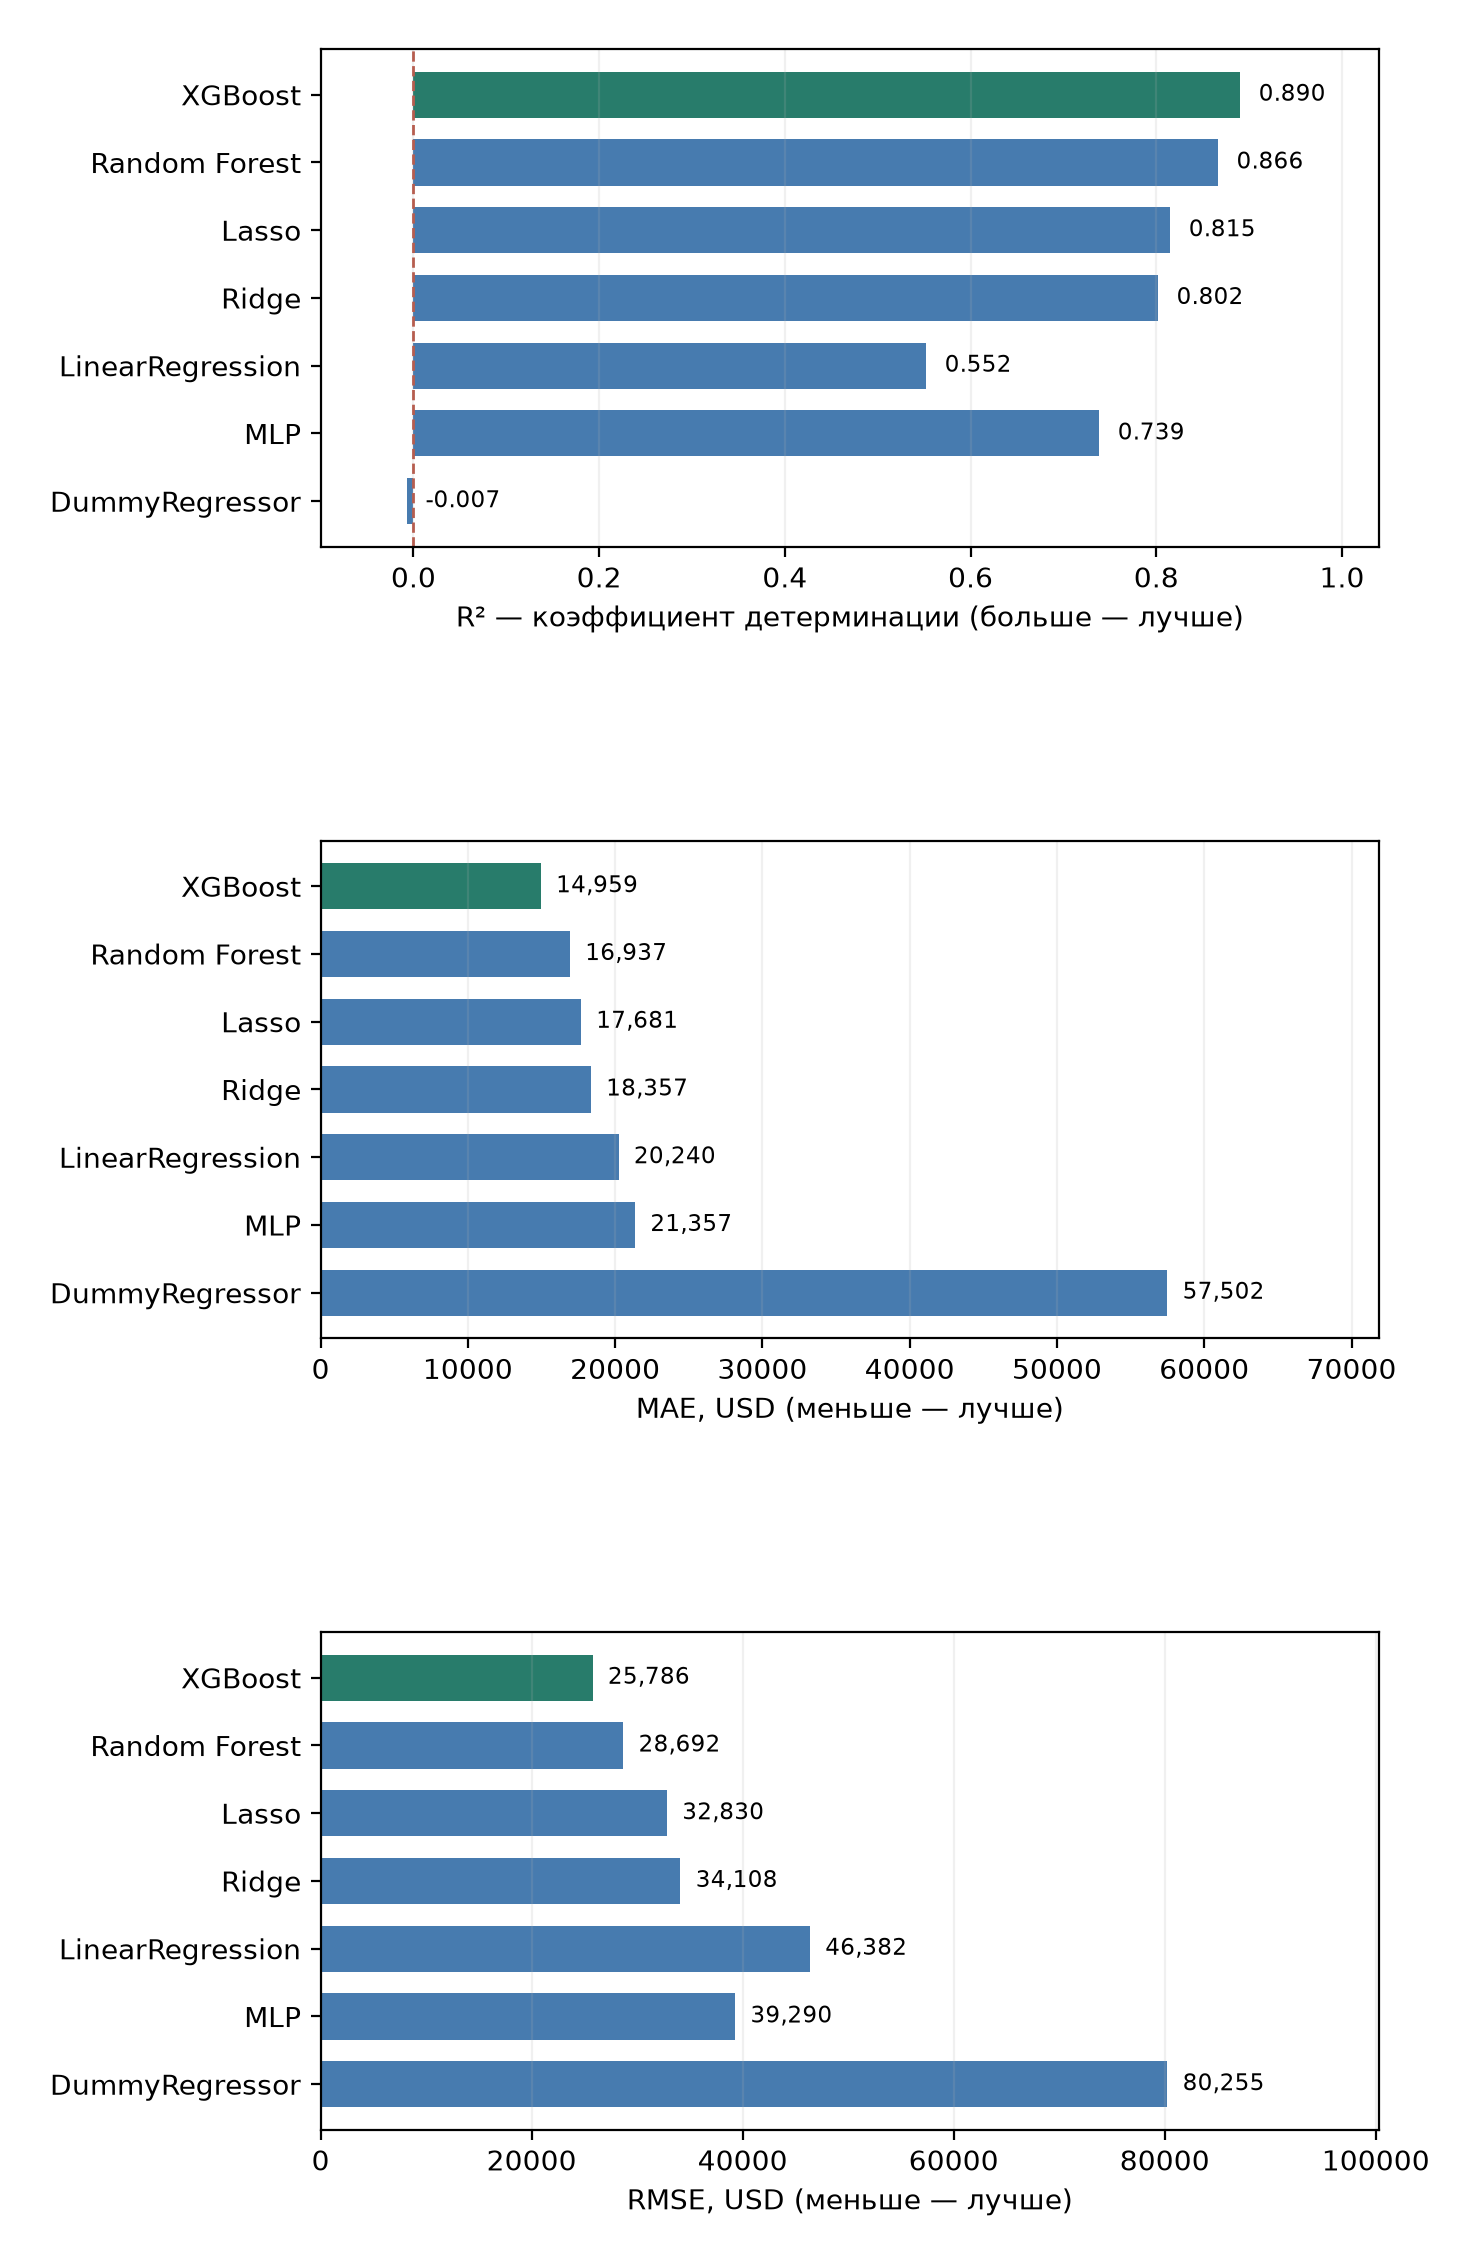

*Рисунок 3.1 — Средние значения R², MAE и RMSE по пяти фолдам.*

In [4]:
def show_figure(name, caption):
    path = FIGURES / name
    if path.exists():
        display(Image(filename=str(path), width=520))
    else:
        print(f"Рисунок ещё не создан: {path}")
    display(Markdown(f"*{caption}*"))

show_figure("3_1_cv_mae.png", "Рисунок 3.1 — Средние значения R², MAE и RMSE по пяти фолдам.")

На рисунке 3.1 сравниваются три метрики, каждая на собственной шкале. **XGBoost** показывает наибольший средний R² (0,8903) и наименьшие ошибки MAE (14 959 USD) и RMSE (25 786 USD). Ближайший конкурент по средней абсолютной ошибке — Random Forest (16 937 USD). DummyRegressor заметно уступает обучаемым алгоритмам, поскольку ориентируется только на среднюю цену обучающих объектов. Значения MAE и RMSE выражены в долларах, а R² не имеет единиц измерения.

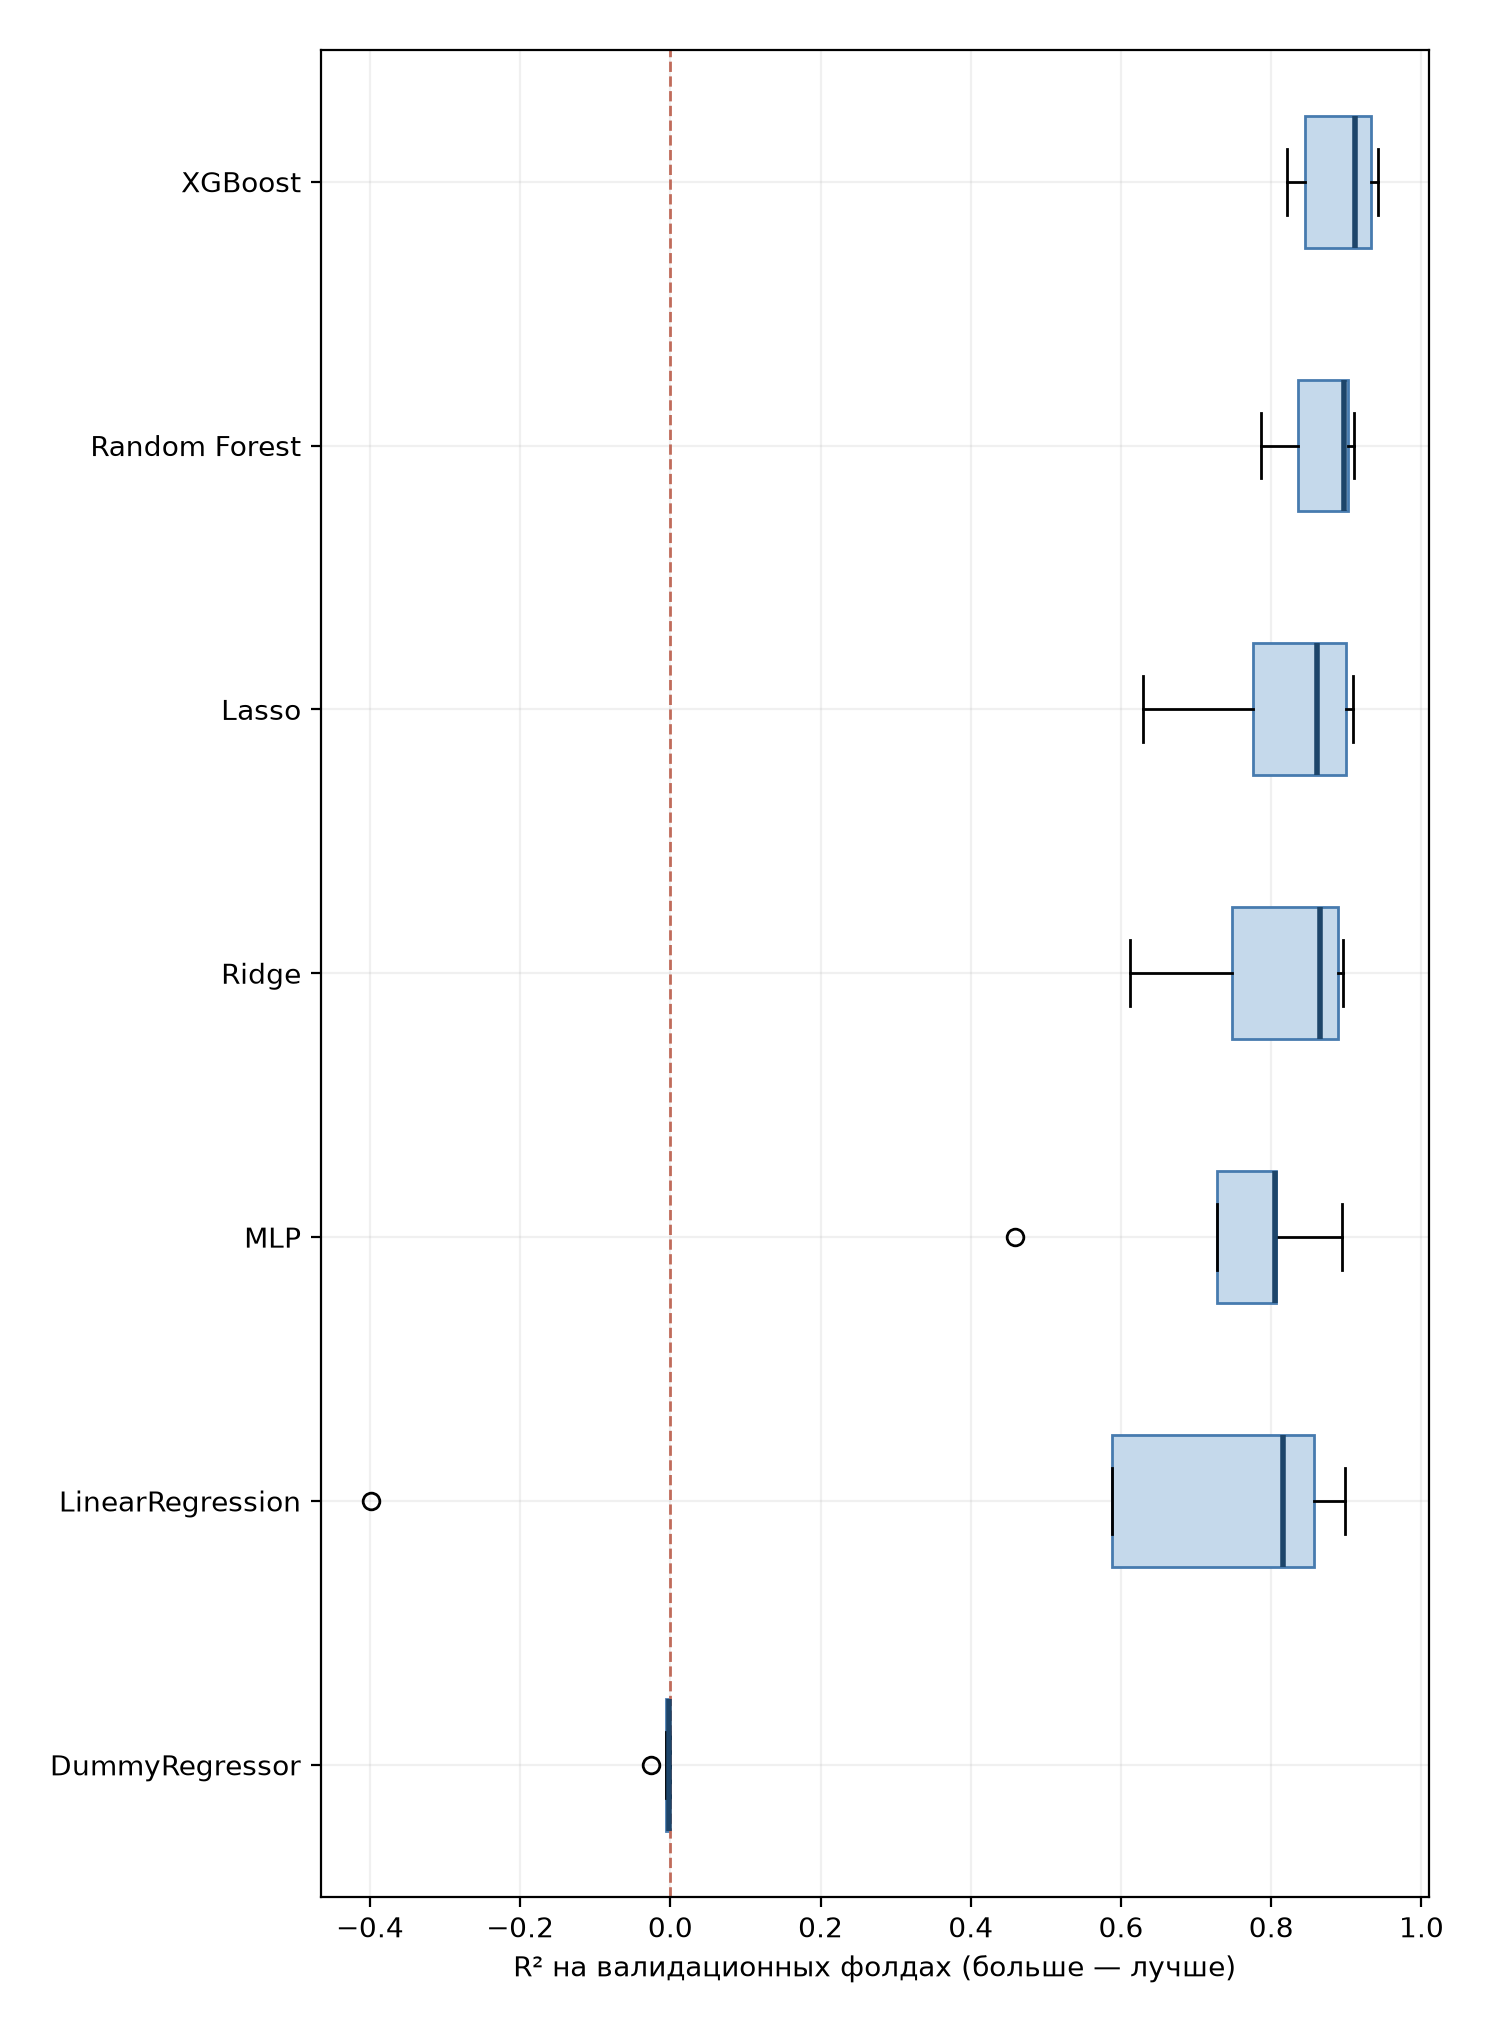

*Рисунок 3.2 — Распределение R² по пяти проверочным фолдам.*

In [5]:
show_figure("3_2_cv_r2_folds.png", "Рисунок 3.2 — Распределение R² по пяти проверочным фолдам.")

На рисунке 3.2 виден разброс качества при изменении состава обучающих и проверочных данных. У XGBoost и Random Forest значения R² относительно стабильны, стандартные отклонения составляют 0,0488 и 0,0481 соответственно. У LinearRegression разброс значительно выше (0,4874), а на третьем фолде получено отрицательное значение R² = −0,3986. Это означает, что на данном блоке модель ошибалась сильнее, чем прогноз среднего значения цены. Регуляризованные Ridge и Lasso уменьшили нестабильность обычной линейной регрессии, но сохранили чувствительность к отдельным разбиениям.

### Сопоставление качества и устойчивости

Рисунки 3.1 и 3.2 совместно показывают преимущество XGBoost: модель достигает минимальных средних ошибок и сохраняет сравнительно стабильное качество на разных фолдах. Random Forest является ближайшим конкурентом. У LinearRegression высокий тренировочный R² не сопровождается сопоставимым результатом на проверочных данных, что согласуется с выявленной ранее нестабильностью коэффициентов при зависимых признаках. Выбор XGBoost на данном этапе основан на пятифолдовой CV базовых конфигураций, а не на внешнем тесте или результатах последующего подбора параметров.

In [6]:
best = cv_summary.iloc[0]
second = cv_summary.iloc[1]
linear = cv_summary.loc[cv_summary.Model == "LinearRegression"].iloc[0]
mlp_cv = cv_summary.loc[cv_summary.Model == "MLP"].iloc[0]
print(
    f"Лидер по средней MAE — {best.Model}: {best.MAE_mean:,.0f} USD, "
    f"RMSE = {best.RMSE_mean:,.0f} USD, R² = {best.R2_mean:.4f} "
    f"(std R² = {best.R2_std:.4f})."
)
print(
    f"Разница MAE относительно второй модели ({second.Model}): "
    f"{second.MAE_mean-best.MAE_mean:,.0f} USD "
    f"({(second.MAE_mean-best.MAE_mean)/second.MAE_mean*100:.1f}%)."
)
print(
    f"LinearRegression: средний R² train = {linear.Train_R2_mean:.4f}, "
    f"CV R² = {linear.R2_mean:.4f}, std = {linear.R2_std:.4f}."
)
print(
    f"MLP: средний R² train = {mlp_cv.Train_R2_mean:.4f}, "
    f"CV R² = {mlp_cv.R2_mean:.4f}, std = {mlp_cv.R2_std:.4f}."
)

Лидер по средней MAE — XGBoost: 14,959 USD, RMSE = 25,786 USD, R² = 0.8903 (std R² = 0.0488).
Разница MAE относительно второй модели (Random Forest): 1,978 USD (11.7%).
LinearRegression: средний R² train = 0.9552, CV R² = 0.5521, std = 0.4874.
MLP: средний R² train = 0.9119, CV R² = 0.7385, std = 0.1496.


## Диагностика прогнозов и остатков лучшей по CV модели

Используем **out-of-fold (OOF)** прогнозы: каждый обучающий объект предсказывается моделью, которая его не видела во время обучения соответствующего фолда. Это позволяет получить графики без привлечения внешнего теста.

OOF-объектов: 1168


,Id,SalePrice,OOF_Pred,Residual
0,493,172785.0,175493.780,-2708.781250
1,1215,134500.0,126765.086,7734.914062
2,763,215200.0,205422.890,9777.109375
3,158,269500.0,266012.160,3487.843750
4,1156,218000.0,192518.030,25481.968750


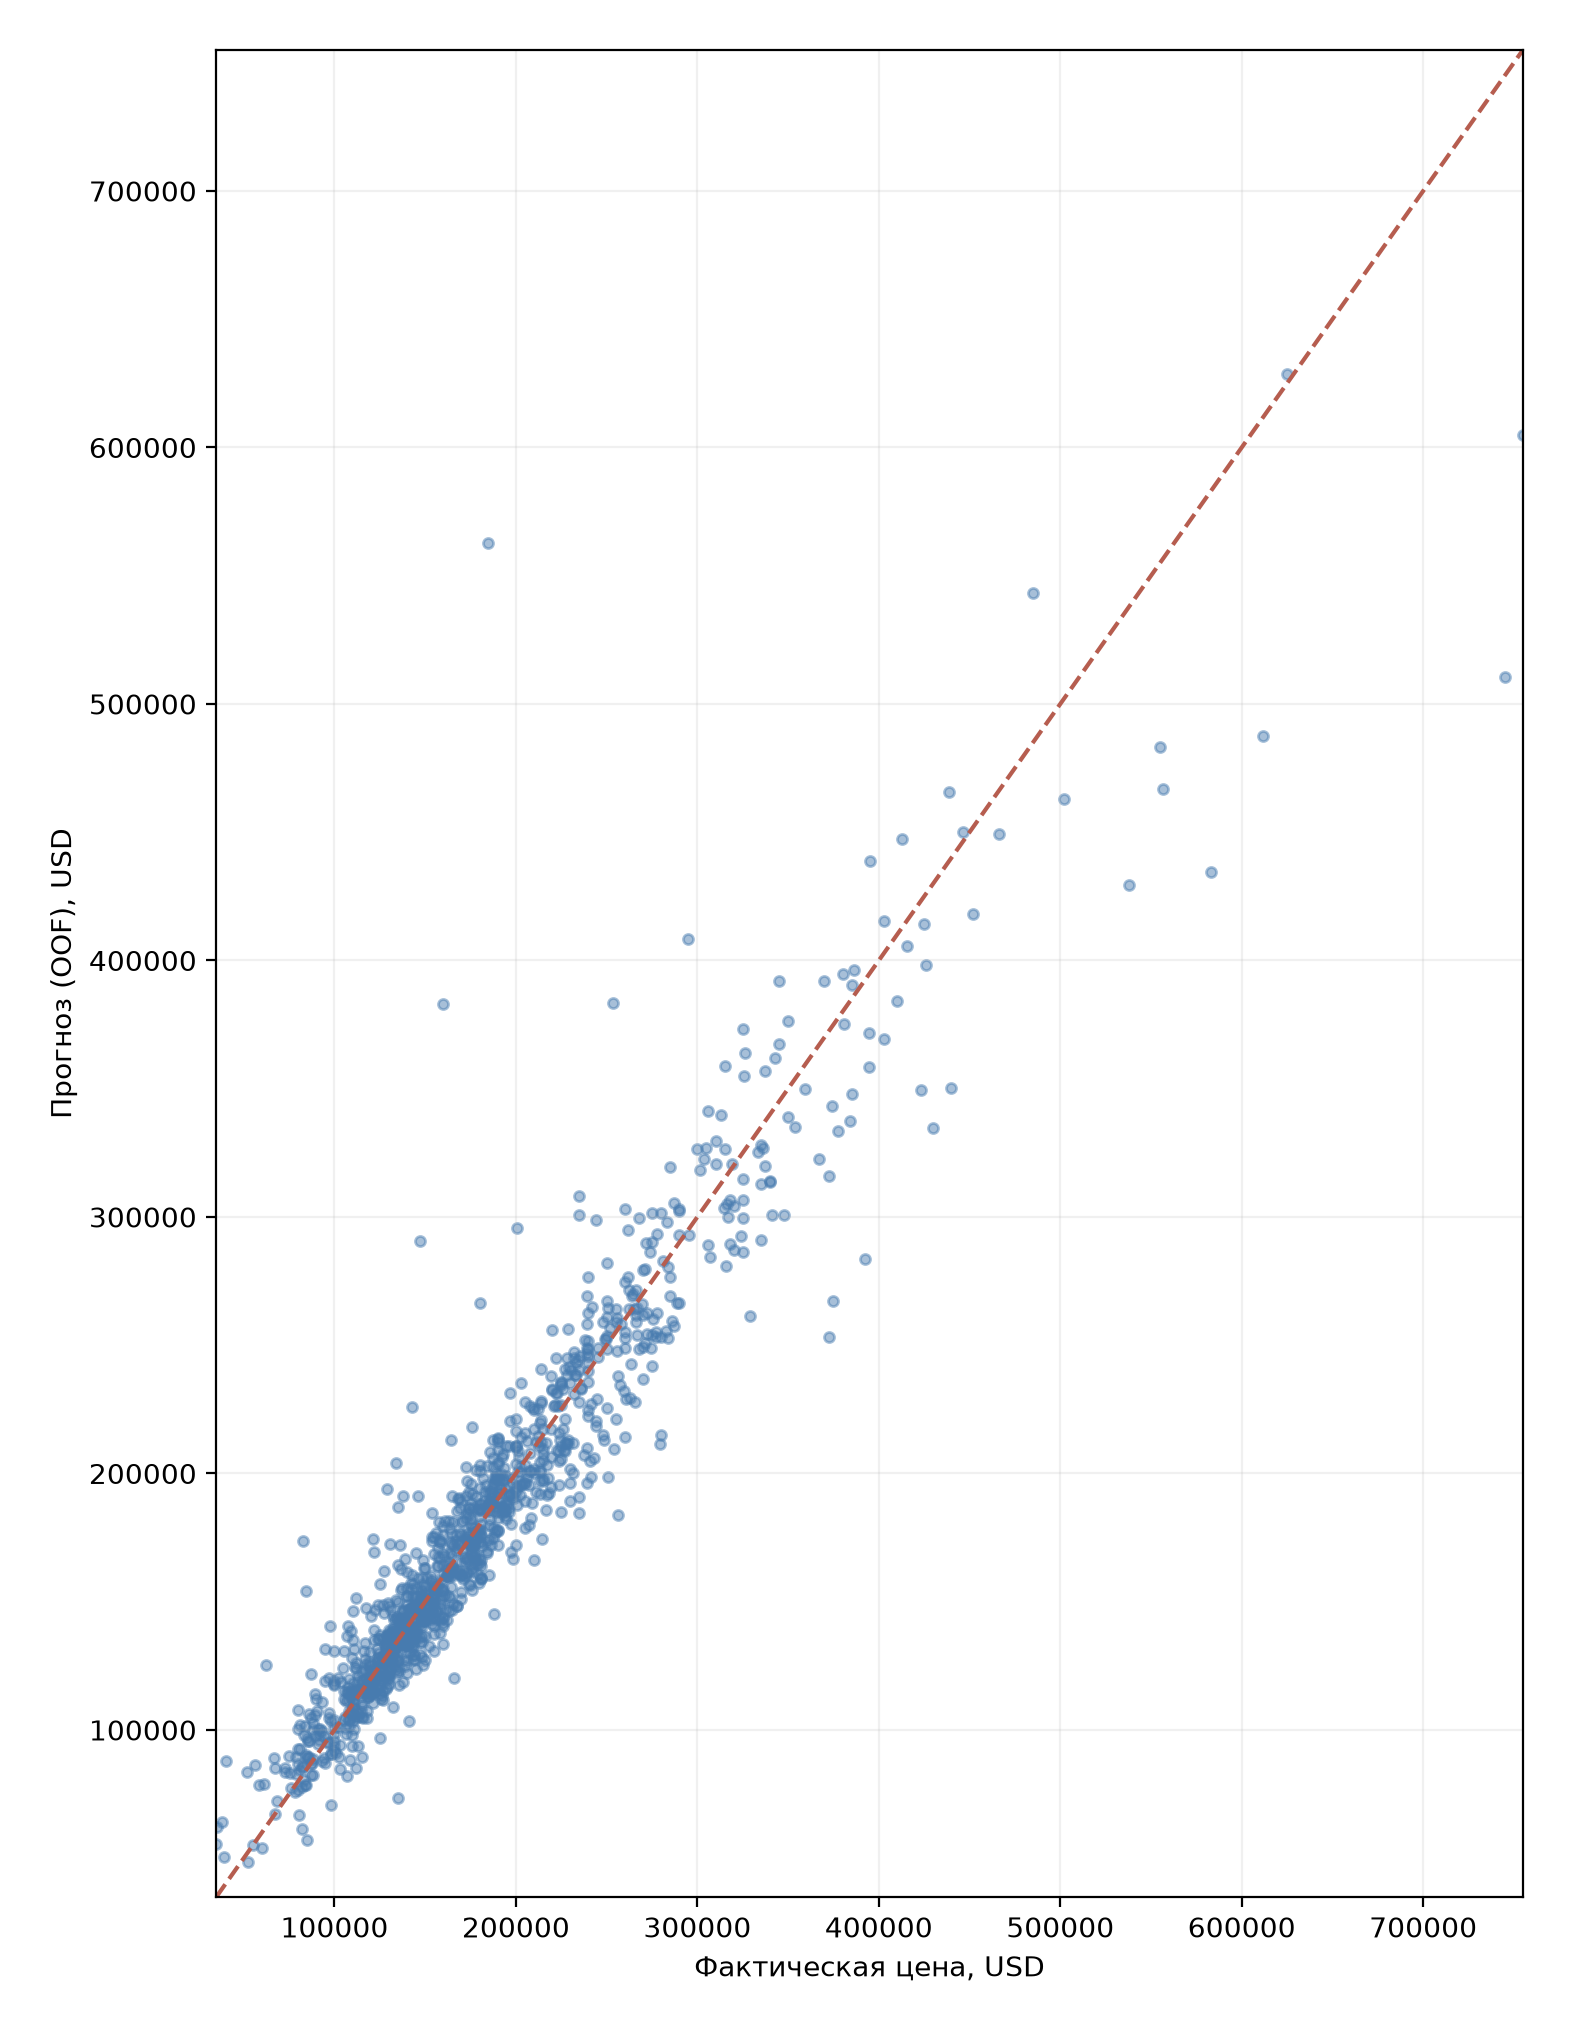

*Рисунок 3.3 — Фактические цены и OOF-прогнозы выбранной модели.*

In [7]:
oof = pd.read_csv(RESULTS / "oof_predictions.csv")
print("OOF-объектов:", len(oof))
display(oof.head())

show_figure("3_3_oof_actual_vs_pred.png", "Рисунок 3.3 — Фактические цены и OOF-прогнозы выбранной модели.")

На рисунке 3.3 большинство точек сосредоточено около диагонали идеального совпадения прогноза с фактической стоимостью. Это свидетельствует о сравнительно небольших ошибках для основной массы объектов. Одновременно видны отдельные значительные отклонения, особенно в области высоких цен. При этом каждая точка представляет прогноз для дома, который не входил в обучающий фолд соответствующей модели.

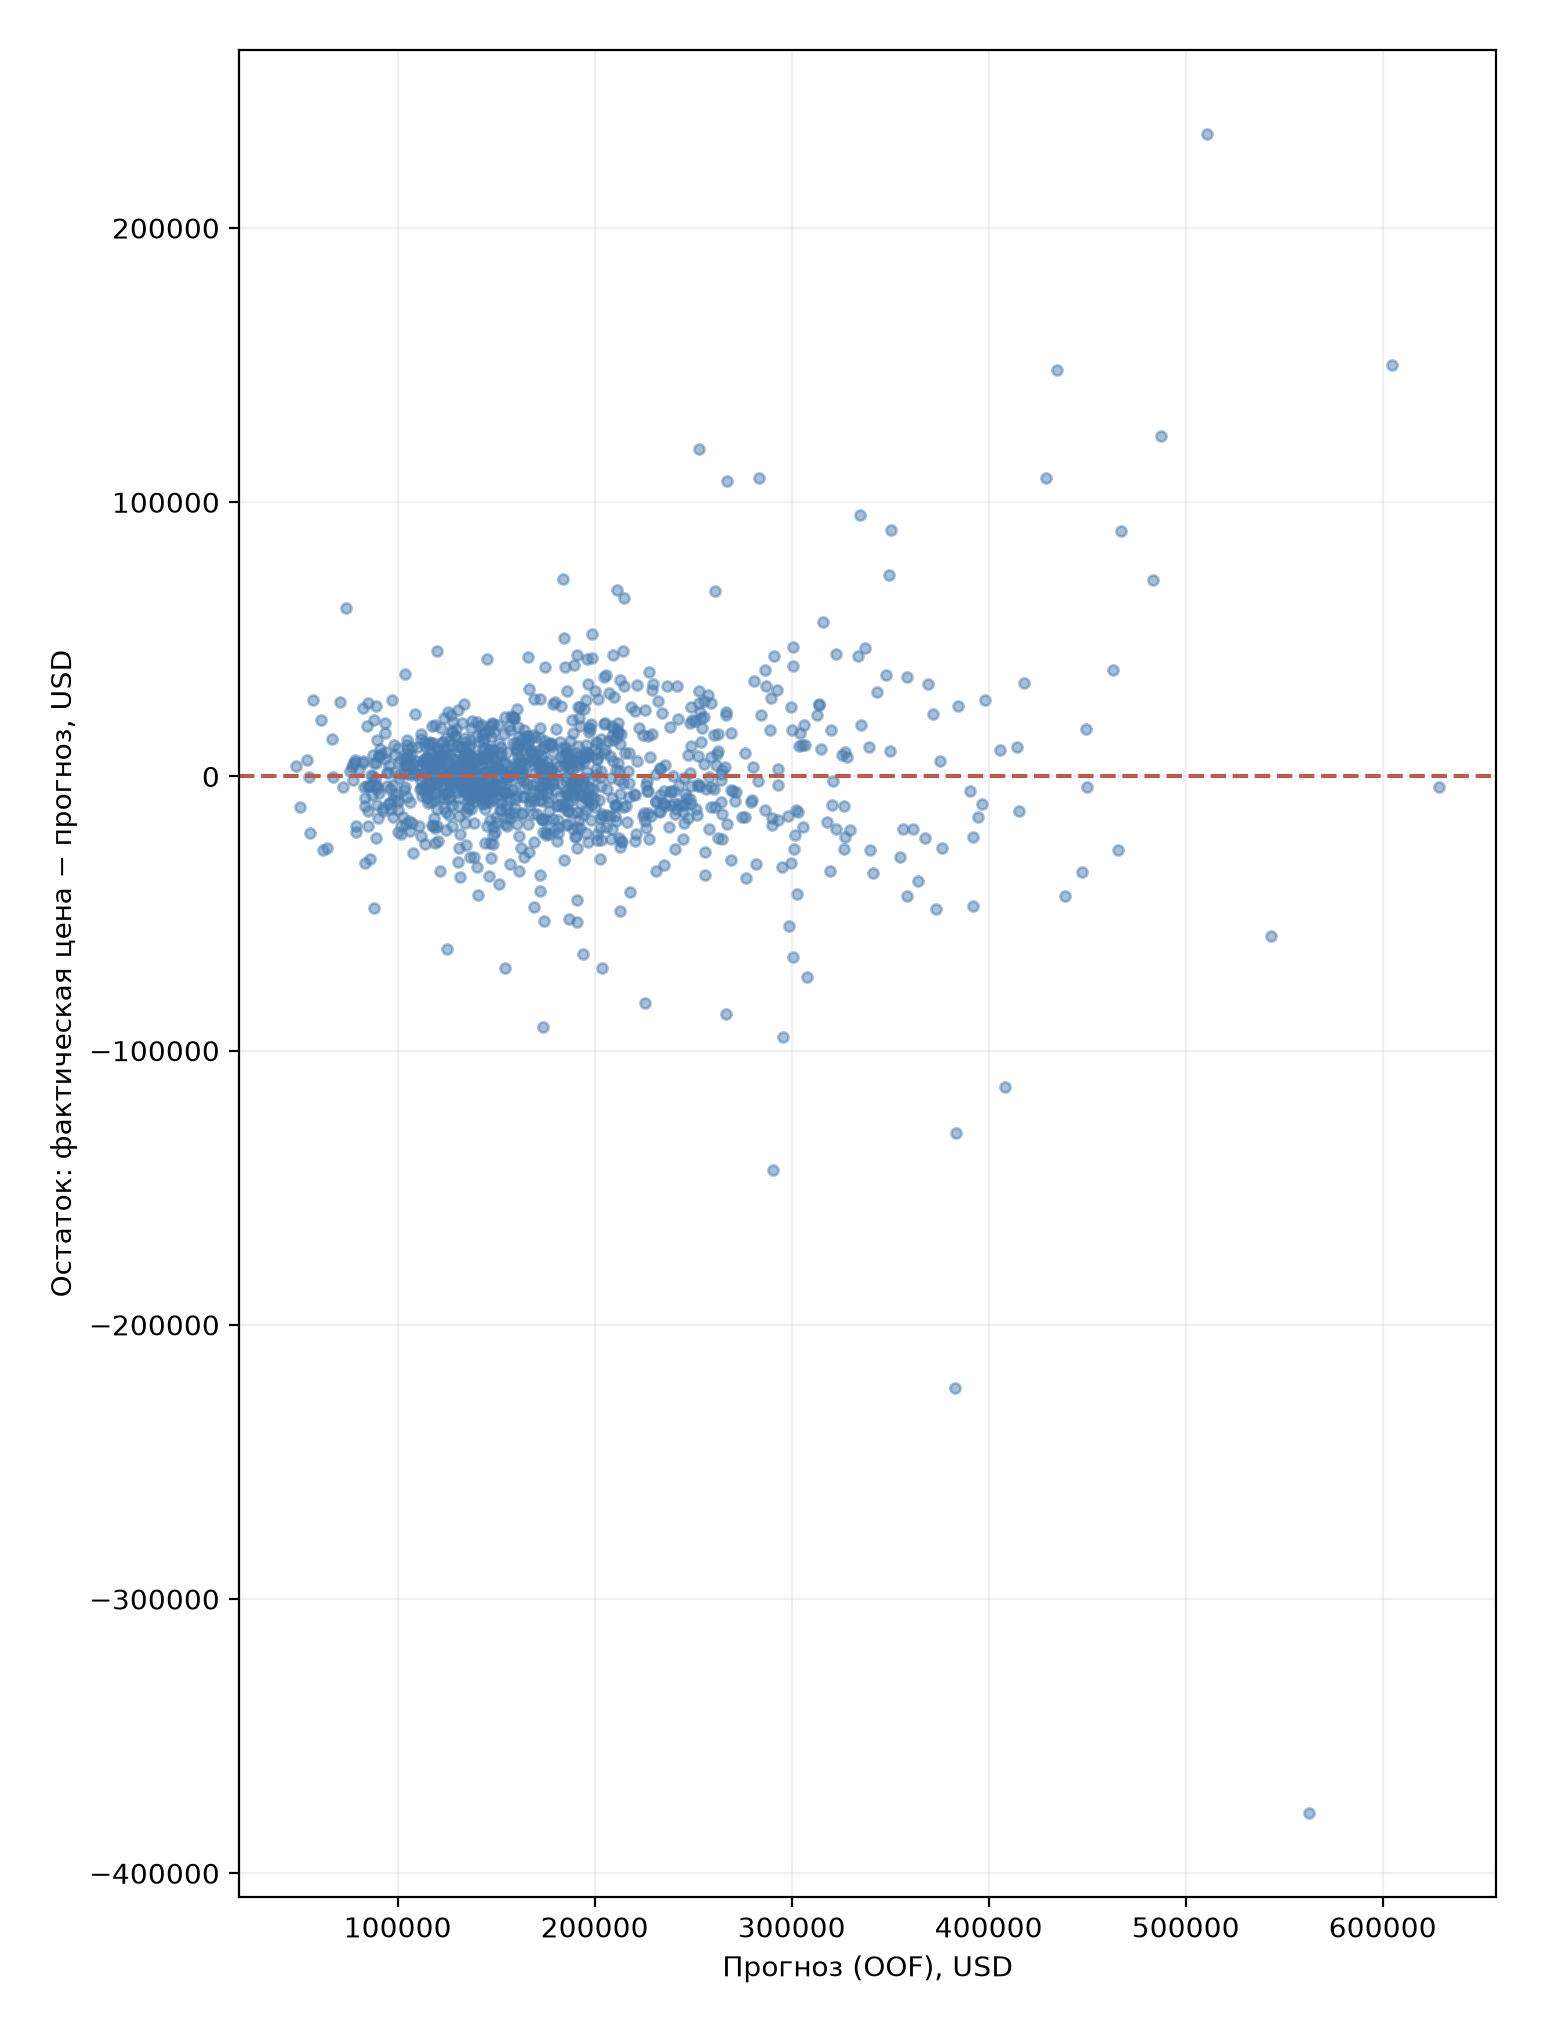

*Рисунок 3.4 — Остатки OOF-прогнозов относительно предсказанной цены.*

In [8]:
show_figure("3_4_oof_residuals.png", "Рисунок 3.4 — Остатки OOF-прогнозов относительно предсказанной цены.")

На рисунке 3.4 остаток рассчитывается как фактическая цена минус прогноз. Точки по обе стороны нулевой линии означают недооценку и переоценку недвижимости соответственно. Для основной группы домов ошибки относительно компактны, но с увеличением прогнозируемой стоимости разброс становится больше. Отдельные крупные остатки показывают, что модель значительно ошибается при оценке некоторых нетипичных объектов.

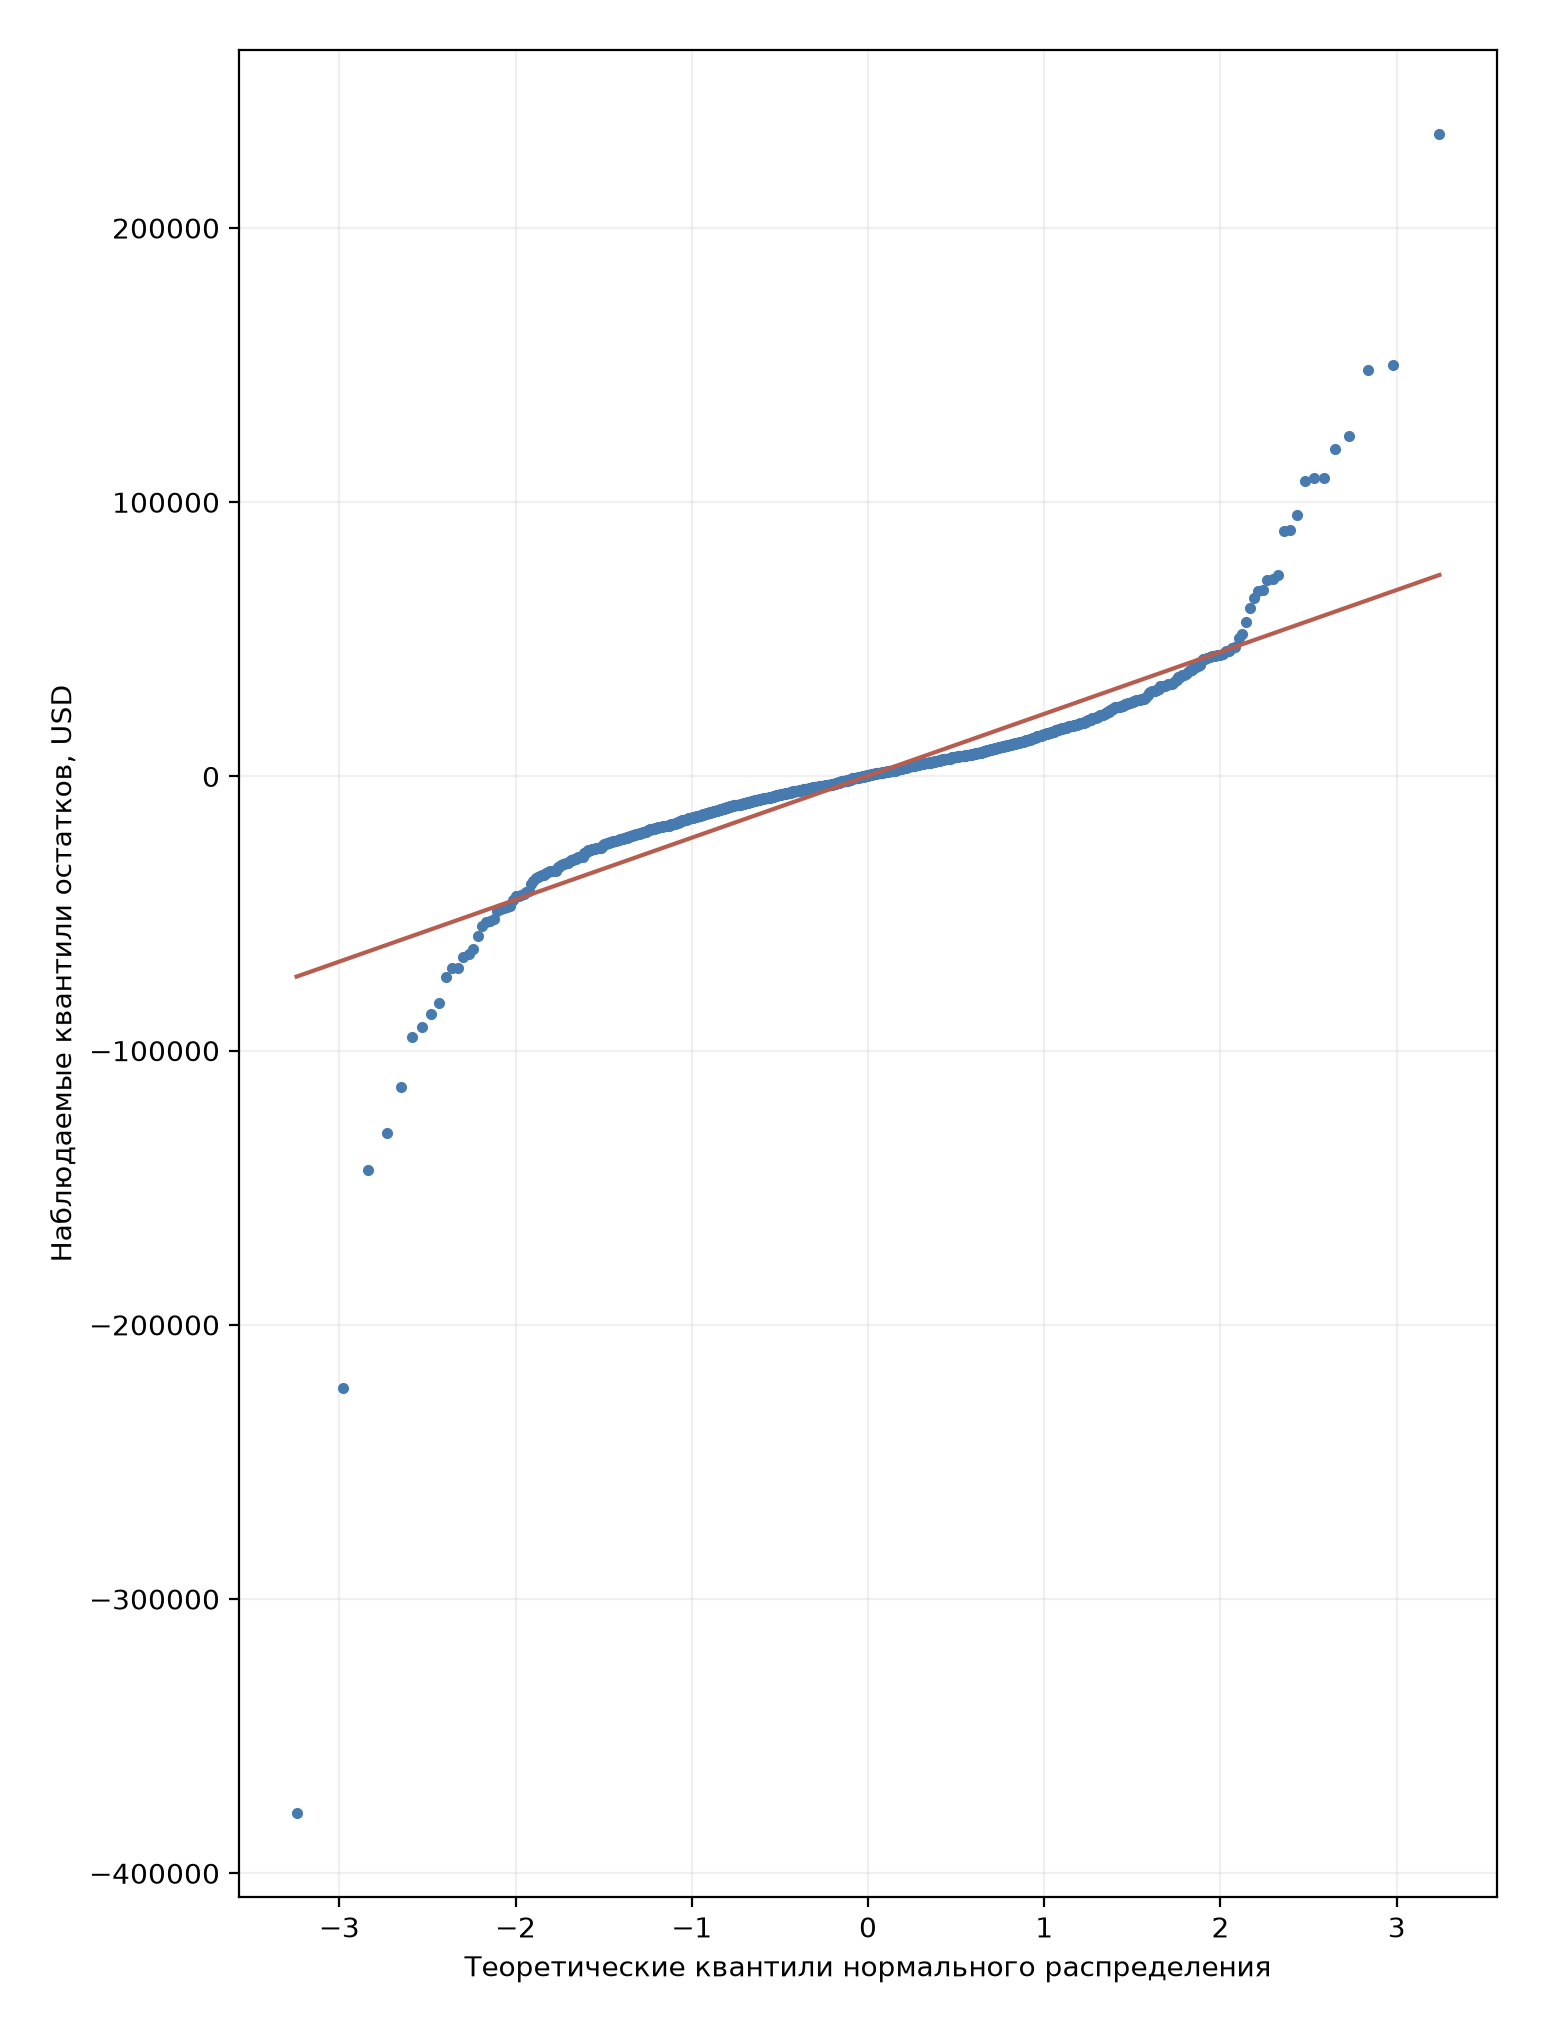

*Рисунок 3.5 — Q–Q диаграмма распределения остатков OOF-прогнозов.*

In [9]:
show_figure("3_5_oof_qq.png", "Рисунок 3.5 — Q-Q диаграмма распределения остатков OOF-прогнозов.")

На рисунке 3.5 центральная часть точек расположена сравнительно близко к теоретической прямой нормального распределения, но в обоих хвостах заметны сильные отклонения. Это согласуется с наличием небольшого числа крупных ошибок, выявленных на предыдущих двух рисунках. Нормальность остатков не является обязательным условием применения XGBoost, поэтому график используется для диагностики распределения ошибок, а не для исключения алгоритма.

### Совместная оценка прогнозов и остатков

Рисунки 3.3–3.5 показывают, что **XGBoost хорошо описывает большинство исторических сделок**, однако качество неоднородно и ухудшается на отдельных нетипичных и дорогих объектах. Такой вывод согласуется с низкой средней MAE, но одновременно объясняет, почему RMSE остаётся заметно выше MAE. Дальнейшее исследование крупных отклонений и локальных вкладов признаков запланировано для ЛР №5.

In [10]:
oof = oof.assign(Absolute_Error=oof["Residual"].abs())
print("Максимальные абсолютные ошибки OOF (не внешний тест):")
display(oof.nlargest(5, "Absolute_Error")[["Id", "SalePrice", "OOF_Pred", "Residual", "Absolute_Error"]].round(1))
expensive = oof[oof["SalePrice"] >= 400_000]
regular = oof[oof["SalePrice"] < 400_000]
print(
    f"Дома от 400 000 USD: n={len(expensive)}, "
    f"MAE={expensive.Absolute_Error.mean():,.0f} USD, "
    f"остальные: n={len(regular)}, MAE={regular.Absolute_Error.mean():,.0f} USD."
)
print("Эти подгруппы выделены для диагностики, а не для настройки модели по OOF-результатам.")

Максимальные абсолютные ошибки OOF (не внешний тест):


,Id,SalePrice,OOF_Pred,Residual,Absolute_Error
940,524,184750.0,562757.4,-378007.4,378007.4
1003,1183,745000.0,510658.7,234341.3,234341.3
607,1299,160000.0,383148.2,-223148.2,223148.2
685,692,755000.0,604823.0,150177.0,150177.0
423,804,582933.0,434644.9,148288.1,148288.1


Дома от 400 000 USD: n=24, MAE=63,465 USD, остальные: n=1144, MAE=13,944 USD.
Эти подгруппы выделены для диагностики, а не для настройки модели по OOF-результатам.


## Обучение MLP и ранняя остановка

Многослойный персептрон использует два скрытых слоя (64 и 32 нейрона), функцию активации ReLU, оптимизатор Adam и механизм Early Stopping. Обучение направлено на снижение Training Loss, рассчитанного по стандартизированной целевой переменной. Однако улучшение на обучающих данных не гарантирует роста Validation R². При ранней остановке сохраняются и затем восстанавливаются веса, соответствующие лучшему результату внутренней валидации.

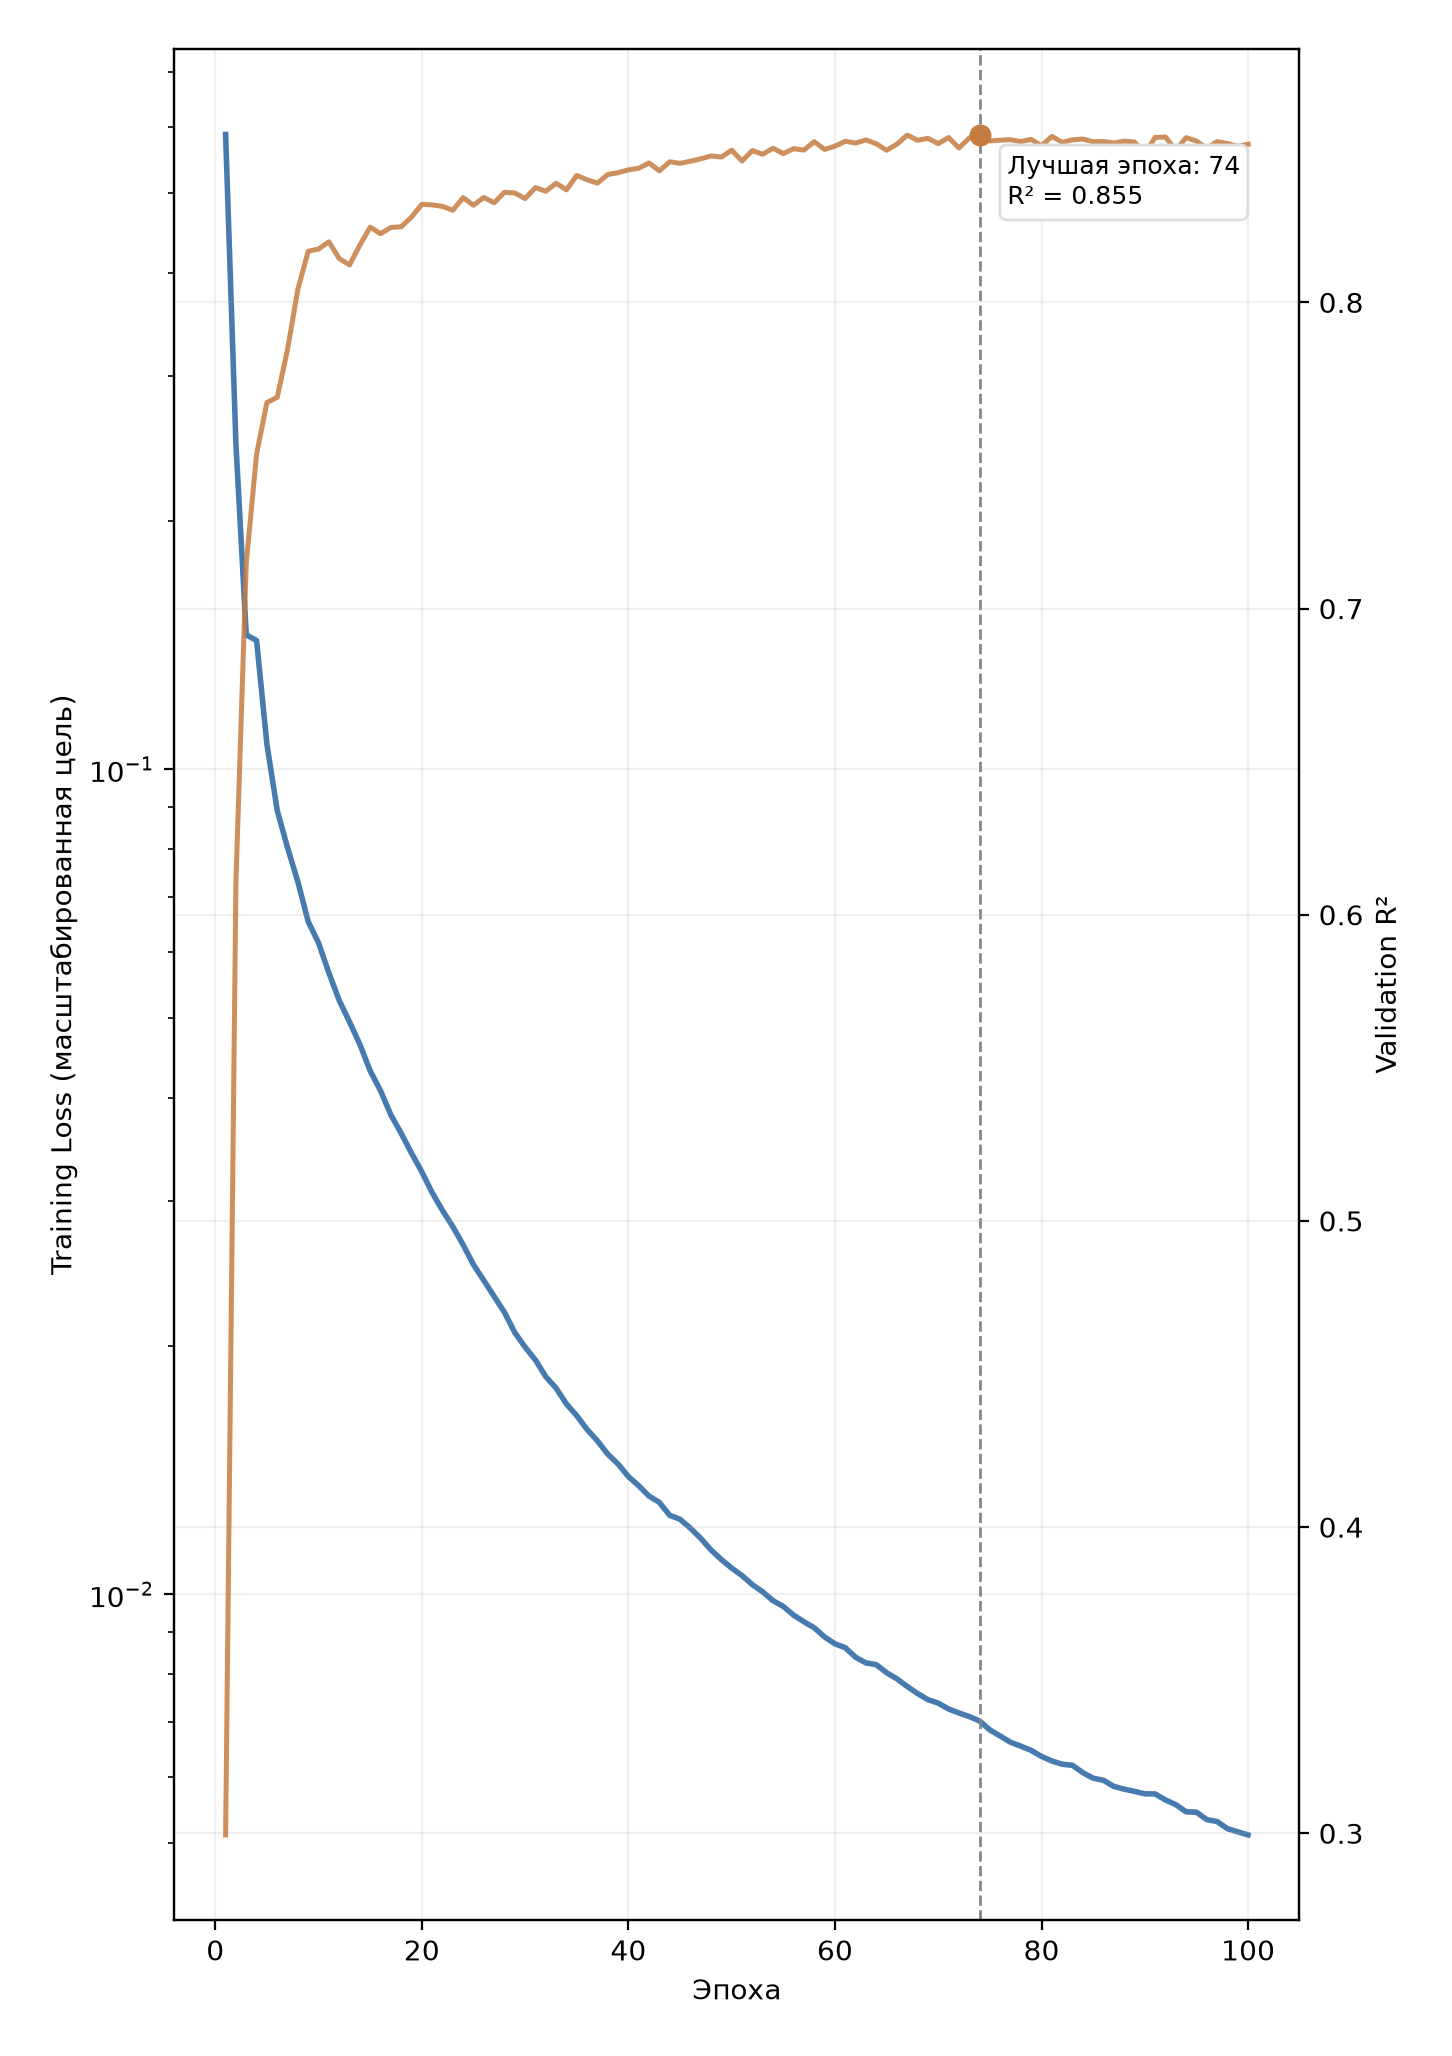

*Рисунок 3.6 — Training Loss и Validation R² нейросети MLP на полном внешнем train.*

In [11]:
show_figure("3_6_mlp_training.png", "Рисунок 3.6 — Training Loss и Validation R² нейросети MLP на полном внешнем train.")

In [12]:
import json
mlp_info_path = RESULTS / "mlp_training_summary.json"
if mlp_info_path.exists():
    mlp_info = json.loads(mlp_info_path.read_text(encoding="utf-8"))
    display(pd.DataFrame([{
        "Эпох выполнено": mlp_info["epochs_run"],
        "Лучшая эпоха": mlp_info["best_epoch"],
        "Loss первой эпохи": mlp_info["first_loss"],
        "Loss лучшей эпохи": mlp_info["best_epoch_loss"],
        "Loss последней эпохи": mlp_info["last_loss"],
        "Лучший Validation R²": mlp_info["best_validation_r2"],
        "Validation R² последней эпохи": mlp_info["last_validation_r2"],
    }]).round(5))
    best_r2 = mlp_info["best_validation_r2"]
    last_r2 = mlp_info["last_validation_r2"]
    if last_r2 < best_r2:
        explanation = (
            "После лучшей эпохи качество на внутренней валидации снизилось, "
            "хотя Training Loss к последней эпохе стал меньше. "
            "Это характерный признак переобучения или нестабильности качества."
        )
    else:
        explanation = "В последней эпохе достигнут лучший валидационный результат."
    display(Markdown(
        f"Нейросеть обучалась **{mlp_info['epochs_run']} эпох**, "
        f"наилучший Validation R² = **{best_r2:.4f}** достигнут "
        f"на **{mlp_info['best_epoch']}-й эпохе**. "
        f"К концу обучения Validation R² = **{last_r2:.4f}**. "
        + explanation + " Механизм Early Stopping сохраняет/восстанавливает "
        "лучшие веса, а `loss_` относится к последней эпохе, поэтому "
        "его нельзя считать ошибкой восстановленной модели. "
        "Это **не** история предыдущего самостоятельного эксперимента с 38 эпохами."
    ))
else:
    print("Нет mlp_training_summary.json. Запусти python refresh_lr03_outputs.py — пересчитывать все CV-фолды не нужно.")

,Эпох выполнено,Лучшая эпоха,Loss первой эпохи,Loss лучшей эпохи,Loss последней эпохи,Лучший Validation R²,Validation R² последней эпохи
0,100,74,0.58798,0.00702,0.00511,0.85482,0.85164


Нейросеть обучалась **100 эпох**, наилучший Validation R² = **0.8548** достигнут на **74-й эпохе**. К концу обучения Validation R² = **0.8516**. После лучшей эпохи качество на внутренней валидации снизилось, хотя Training Loss к последней эпохе стал меньше. Это характерный признак переобучения или нестабильности качества. Механизм Early Stopping сохраняет/восстанавливает лучшие веса, а `loss_` относится к последней эпохе, поэтому его нельзя считать ошибкой восстановленной модели. Это **не** история предыдущего самостоятельного эксперимента с 38 эпохами.

Сопоставление двух кривых на рисунке 3.6 показывает, почему завершать обучение только по минимальному Training Loss недостаточно. В данной версии MLP лучший валидационный результат был достигнут раньше последней эпохи, после чего функция потерь продолжала уменьшаться без соответствующего улучшения Validation R². Такой характер динамики указывает на риск переобучения и обосновывает использование Early Stopping. Результаты этого запуска не следует смешивать с первоначальным учебным экспериментом, в котором было выполнено 38 эпох.

## Внешний тест и редкий объект с бассейном

На внешнем тесте приведены те же метрики в USD, они не использовались для выбора алгоритма. Ранее выявленный дом с `PoolQC_Gd` и `SalePrice = 274970` представлен отдельно. В train категория `PoolQC_Gd` встречалась лишь у одного объекта. Нельзя заключить, что именно бассейн полностью объясняет ошибку какой-либо модели.

In [13]:
display(test_summary.round(3))
case_file = RESULTS / "rare_pool_case.csv"
if case_file.exists():
    rare_case = pd.read_csv(case_file)
    display(rare_case.sort_values("Abs_error_USD").round(2))
else:
    print("Нет ранее исследованного объекта в текущем тестовом разбиении.")

,Model,R2,MAE,RMSE
0,XGBoost,0.894,14847.150,24370.473
1,Lasso,0.887,16371.889,25194.008
2,Ridge,0.896,16705.161,24209.832
3,Random Forest,0.871,18076.338,26978.115
4,MLP,0.875,18158.471,26547.345
5,LinearRegression,0.639,20134.919,45050.284
6,DummyRegressor,-0.000,57678.271,75000.384


,Model,Id,Actual_USD,Pred_USD,Abs_error_USD
6,MLP,1424,274970.0,282023.19,7053.19
2,Ridge,1424,274970.0,203450.09,71519.91
4,Random Forest,1424,274970.0,184588.50,90381.50
0,DummyRegressor,1424,274970.0,181210.55,93759.45
5,XGBoost,1424,274970.0,160275.66,114694.34
3,Lasso,1424,274970.0,110965.61,164004.39
1,LinearRegression,1424,274970.0,895067.14,620097.14


## Подбор параметров XGBoost

Подбор проведён методом **RandomizedSearchCV** на трёх фолдах внешней обучающей выборки. Целевая метрика поиска — MAE в USD, минимизация ошибки. Перебираются `n_estimators` (количество деревьев), `max_depth` (сложность каждого дерева), `learning_rate` (шаг бустинга), `subsample` (доля объектов), `colsample_bytree` (доля признаков), `min_child_weight` (минимальные требования к разделению) и `reg_lambda` (L2-штраф).

**Обоснование диапазонов:** маленькая глубина 2–4 и `min_child_weight` 1–5 ограничивают сложность на небольшом датасете, шаг 0.025–0.08 и 200–450 деревьев позволяют сравнить медленное/быстрое обучение, подвыборки строк/признаков и `reg_lambda` помогают бороться с переобучением. Выбор диапазонов — инженерная гипотеза, а не гарантия оптимума.

В полном пространстве **2187** комбинаций, текущий пробный поиск изучил только **8**, поэтому результат не следует считать глобальным оптимумом. Трёхфолдовая MAE победителя по использованным при поиске разбиениям потенциально оптимистична. Значения из пятифолдовой CV относятся к **базовой**, а не автоматически к подобранной конфигурации.

In [14]:
params_path = RESULTS / "xgboost_tuning.json"
trials_path = RESULTS / "xgboost_tuning_trials.csv"
if params_path.exists():
    config = json.loads(params_path.read_text(encoding="utf-8"))
    best_params = {key.removeprefix("model__"): val
                   for key, val in config["best_params"].items()}
    base_params = {
        "n_estimators": 300, "max_depth": 3, "learning_rate": 0.05,
        "subsample": 0.8, "colsample_bytree": 0.8,
        "min_child_weight": 1, "reg_lambda": 1.0,
    }
    param_names = list(base_params)
    display(pd.DataFrame({
        "Параметр": param_names,
        "Базовая": [base_params[k] for k in param_names],
        "Выбранная": [best_params.get(k) for k in param_names],
    }))
    print(f"Лучшая MAE в 3-Fold поиске: {config['cv3_mae_usd']:,.2f} USD")
    print("При подборе использовано 8 случайных комбинаций из 2187 возможных.")
    if trials_path.exists():
        trials = pd.read_csv(trials_path)
        best_trials = trials.nsmallest(5, "rank_test_score")
        display(pd.DataFrame({
            "Ранг": best_trials["rank_test_score"],
            "MAE (3-Fold), USD": -best_trials["mean_test_score"],
            "Std MAE, USD": best_trials["std_test_score"],
            "Параметры": best_trials["params"],
        }).round(2))
    display(Markdown(
        "Среди исследованных конфигураций выбрана конфигурация с меньшим шагом обучения, "
        "большим количеством деревьев и глубиной 4 вместо 3. Это **результат поиска** "
        "по выбранной метрике, а не доказательство независимого прироста качества. "
        "В дальнейших экспериментах сравним базовую и настроенную модели "
        "на одинаковых новых валидационных разбиениях либо через вложенную CV."
    ))
else:
    print("Подбор не выполнялся. Для запуска: python run_lr03.py --tune-xgb")

,Параметр,Базовая,Выбранная
0,n_estimators,300.00,450.000
1,max_depth,3.00,4.000
2,learning_rate,0.05,0.025
3,subsample,0.80,0.750
4,colsample_bytree,0.80,1.000
5,min_child_weight,1.00,1.000
6,reg_lambda,1.00,1.000


Лучшая MAE в 3-Fold поиске: 14,967.88 USD
При подборе использовано 8 случайных комбинаций из 2187 возможных.


,Ранг,"MAE (3-Fold), USD","Std MAE, USD",Параметры
4,1,14967.88,989.67,"{'model__subsample': 0.75, 'model__reg_lambda'..."
3,2,15426.67,1142.43,"{'model__subsample': 0.75, 'model__reg_lambda'..."
5,3,15551.46,1023.54,"{'model__subsample': 0.75, 'model__reg_lambda'..."
2,4,15611.57,639.13,"{'model__subsample': 1.0, 'model__reg_lambda':..."
6,5,15875.23,1085.94,"{'model__subsample': 0.9, 'model__reg_lambda':..."


Среди исследованных конфигураций выбрана конфигурация с меньшим шагом обучения, большим количеством деревьев и глубиной 4 вместо 3. Это **результат поиска** по выбранной метрике, а не доказательство независимого прироста качества. В дальнейших экспериментах сравним базовую и настроенную модели на одинаковых новых валидационных разбиениях либо через вложенную CV.

## Итоговые выводы

В ходе исследования разработаны и сопоставлены регрессионные модели
для прогнозирования исторической стоимости жилой недвижимости
на основе характеристик объектов. Исходный набор данных содержит
1 460 наблюдений, из которых 1 168 использованы для обучения
и валидации, а 292 выделены в отдельную тестовую выборку.

Проведено сравнение DummyRegressor, LinearRegression, Ridge, Lasso,
Random Forest, XGBoost и многослойного персептрона (MLP).
Качество прогнозирования оценивалось с использованием MAE, RMSE
и коэффициента детерминации R². Для проверки устойчивости моделей
применена пятикратная кросс-валидация с независимой предобработкой
данных внутри каждого разбиения, что исключает использование
статистик валидационных объектов при обучении преобразований.

Наиболее высокое качество в проведённом сравнении продемонстрировала
модель XGBoost. Средний коэффициент детерминации составил 0,8903,
средняя абсолютная ошибка — 14 959 долларов, среднеквадратичная
ошибка (RMSE) — 25 786 долларов. Random Forest также показал
устойчивые результаты, однако уступил XGBoost по основным метрикам.
Линейная регрессия без регуляризации характеризовалась выраженной
нестабильностью качества между разбиениями, что согласуется
с выявленной ранее мультиколлинеарностью признаков.

Анализ прогнозов и остатков показал, что наибольшие отклонения
могут возникать при оценке объектов с нетипичными характеристиками
и высокой стоимостью. Распределение ошибок содержит выраженные
хвосты, что указывает на необходимость учитывать не только
усреднённые метрики, но и отдельные случаи существенных отклонений.
При этом отклонение распределения остатков от нормального
не является самостоятельным основанием для отклонения модели.

Для XGBoost выполнен подбор гиперпараметров с использованием
RandomizedSearchCV и минимизации MAE. Полученная конфигурация
рассматривается как результат ограниченного поиска, а не как
гарантированно оптимальное решение. Дополнительно исследовано
обучение многослойного персептрона, включая динамику функции
потерь, изменение качества на валидационной выборке и применение
механизма ранней остановки для ограничения переобучения.

Таким образом, XGBoost выбран в качестве основного кандидата
для дальнейшего исследования благодаря сочетанию высокой
точности прогнозирования и сравнительно устойчивого качества
на разных разбиениях данных. Дальнейший анализ предусматривает
исследование значимости характеристик недвижимости, объяснение
отдельных прогнозов и оценку ограничений выбранной модели.

In [15]:
leader = cv_summary.iloc[0]
runner = cv_summary.iloc[1]
print(
    f"Для дальнейшего исследования выбрана модель {leader.Model}. "
    f"На 5-Fold CV: MAE = {leader.MAE_mean:,.2f} USD, "
    f"RMSE = {leader.RMSE_mean:,.2f} USD, "
    f"R² = {leader.R2_mean:.4f} ± {leader.R2_std:.4f} (std между фолдами). "
    f"Ближайший конкурент по MAE — {runner.Model} "
    f"({runner.MAE_mean:,.2f} USD)."
)
print(
    "Это предварительный выбор по CV базовых конфигураций. Подбор XGBoost "
    "выполнен отдельно, не выдаём его 3-Fold score за независимое подтверждение."
)

Для дальнейшего исследования выбрана модель XGBoost. На 5-Fold CV: MAE = 14,959.33 USD, RMSE = 25,785.50 USD, R² = 0.8903 ± 0.0488 (std между фолдами). Ближайший конкурент по MAE — Random Forest (16,937.10 USD).
Это предварительный выбор по CV базовых конфигураций. Подбор XGBoost выполнен отдельно, не выдаём его 3-Fold score за независимое подтверждение.
